# W3 · From separate charts to a visual system
## Will a driver score points? Visualizing the C2 pre-race classifier (Formula 1, 2014–2024)

**Business Intelligence · IIB423T-1 · Universidad del Desarrollo** — Maximiliano Sandoval Mosser (Group 06) ·
Instructor: Tomás Fontecilla · Workshop 3 (individual) · November 2026

**What this notebook does.** It draws the three views of my W3 document from the results of our C2 project, first as they
looked in C2 (**before**) and then redesigned with one shared visual system (**after**). It does not train a new model or run a
new EDA: every value comes from the C2 classifier (`2_C2_model.ipynb`).

**Data.** *Formula 1 World Championship (1950–2024)*, Kaggle (user rohanrao), from the Ergast API. Two small files exported
from the executed C2 notebook are in `data/`:

| File | Content |
|---|---|
| `c2_validation_f1_by_season.csv` | F1 of the model and the reference in each validation season (2018–2022) |
| `c2_validation_f1_by_period.csv` | The same F1, pooling the validation predictions of each regulation period |
| `c2_test_predictions.csv` | One row per driver in each test race (2023–2024, 919 rows): actual result, model probability and prediction, reference prediction |

**Reading order.** 0 Setup and visual system · 1 View 1 · 2 View 2 · 3 View 3 · 4 Values used in the document.
Each view is shown **before** (C2 version, same values) and **after** (W3 version). Figures are saved in `figures/`.

## 0. Setup and visual system

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score, confusion_matrix

ROOT = Path.cwd()
DATA, FIG = ROOT / "data", ROOT / "figures"
FIG.mkdir(exist_ok=True)

val = pd.read_csv(DATA / "c2_validation_f1_by_season.csv")
per = pd.read_csv(DATA / "c2_validation_f1_by_period.csv").set_index("period")
test = pd.read_csv(DATA / "c2_test_predictions.csv")
test["top10"] = test["top10"].astype(int)
print(f"Validation seasons: {len(val)} | test rows: {len(test)} | test races: {test['raceId'].nunique()}")
print("matplotlib", matplotlib.__version__, "| pandas", pd.__version__)

Validation seasons: 5 | test rows: 919 | test races: 46
matplotlib 3.11.2 | pandas 3.0.5


### Visual system (rules applied to the three "after" views)
| Element | Rule |
|---|---|
| **Category colours** | **Model = blue** `#2a78d6`. **Reference rule ("grid 1–10 scores") = grey** `#8a8984`. The same colour always means the same method. |
| **Highlight** | **Orange** `#eb6834` only for the one call-out that carries the message of each view (a difference or a share). Never for a category. |
| **Without colour** | Model = **filled** marker or solid bar; reference = **hollow** marker or hatched bar; every series is also named by a direct text label. |
| **Text** | Title = the finding, in one sentence (12 pt, bold, left). Subtitle = what is shown, records, period and *n* (9.5 pt, grey). Axis labels name the measure and unit. Note line at the bottom = how to read it + source (8 pt, grey). |
| **Scales and units** | F1 always with 3 decimals on its 0–1 scale; counts as whole test rows; shares in % with their denominator. Bars start at 0. A zoomed axis is allowed only for position marks (dots), and it is stated in the note. |
| **Labels** | Direct labels next to the marks instead of legends. Numbers next to every mark that is compared. |
| **Regulation period** | Always named in the view; seasons under the 2022 rules sit on a light band `#f0efec`. |
| **Layout** | Same width (8 in), reading order title → subtitle → chart → note. Seasons in time order, top to bottom. Light grid, no top/right borders. |

In [2]:
MODEL, REF, ACCENT = "#2a78d6", "#8a8984", "#eb6834"
INK, INK2, GRID, BAND = "#1b1e23", "#52514e", "#e6e6e3", "#f0efec"
SOURCE = "Source: Ergast via Kaggle (rohanrao); Group 06 C2 classifier."
W = 8.0                                                      # common figure width in inches

def system_style():
    plt.rcdefaults()
    plt.rcParams.update({
        "figure.facecolor": "white", "axes.facecolor": "white", "font.size": 9, "axes.edgecolor": "#bdbcb7",
        "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
        "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.labelcolor": INK2, "xtick.color": INK2,
        "ytick.color": INK2, "axes.labelsize": 9, "legend.frameon": False})

def headline(fig, title, subtitle, note):
    """Shared text structure: finding (title) -> what is shown (subtitle) -> how to read it + source (note)."""
    fig.text(0.01, 0.985, title, fontsize=12, fontweight="bold", color=INK, ha="left", va="top")
    fig.text(0.01, 0.925, subtitle, fontsize=9.5, color=INK2, ha="left", va="top")
    fig.text(0.01, 0.015, f"{note}  {SOURCE}", fontsize=8, color=INK2, ha="left", va="bottom", wrap=True)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=170, bbox_inches="tight", facecolor="white")
    plt.show()

## 1. View 1 · Validation F1 by season and regulation period
**Question.** Before the final test, did the model predict scorers better than the grid rule, and does that depend on the
regulation period? **Task:** *compare* the F1 of the model and the reference across validation seasons, and *identify* the
seasons where the model is ahead.

### 1a. Before (C2 version)

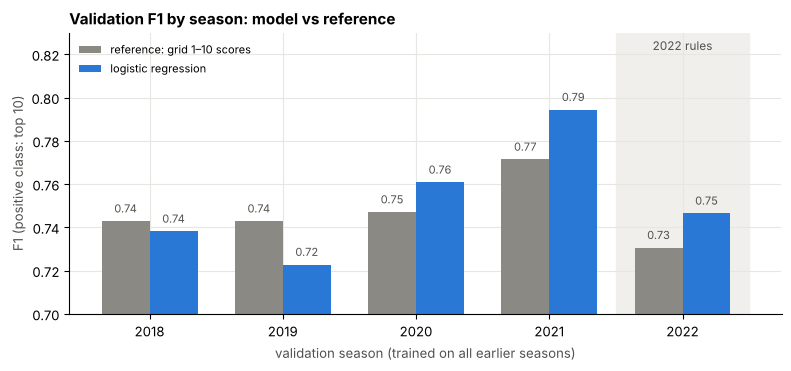

In [3]:
# C2 figure, same code and values as in 2_C2_model.ipynb (grouped bars, axis from 0.70)
plt.rcdefaults()
plt.rcParams.update({"figure.facecolor": "white", "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "axes.labelcolor": INK2, "font.size": 9.5, "legend.frameon": False})
fig, ax = plt.subplots(figsize=(W, 3.8))
x = np.arange(len(val))
ax.axvspan(3.5, 4.5, color="#f0efec", zorder=0)
ax.text(4, 0.822, "2022 rules", ha="center", fontsize=8.5, color=INK2)
ax.bar(x - 0.18, val["f1_reference"], 0.36, color=REF, label="reference: grid 1–10 scores")
ax.bar(x + 0.18, val["f1_model"], 0.36, color="#2a78d6", label="logistic regression")
for i, (r, mo) in enumerate(zip(val["f1_reference"], val["f1_model"])):
    ax.text(i - 0.18, r + 0.004, f"{r:.2f}", ha="center", fontsize=8, color=INK2)
    ax.text(i + 0.18, mo + 0.004, f"{mo:.2f}", ha="center", fontsize=8, color=INK2)
ax.set_xticks(x, val["season"].astype(str))
ax.set(ylim=(0.70, 0.83), xlabel="validation season (trained on all earlier seasons)", ylabel="F1 (positive class: top 10)",
       title="Validation F1 by season: model vs reference")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
save(fig, "V1_before_validation_bars")

**Reading problems.** (1) The bars start at 0.70, so their **lengths** exaggerate the gaps: in 2019 the blue bar looks half
as tall as the grey one, but the F1 difference is only 0.020. (2) Labels with 2 decimals hide differences (2018 reads
"0.74 vs 0.74" although it is 0.743 vs 0.738). (3) The reader must go to the legend to know which colour is which. (4) The
regulation period is only a faint band; the period summary asked for by the feedback is not shown.

### 1b. After (W3 version)

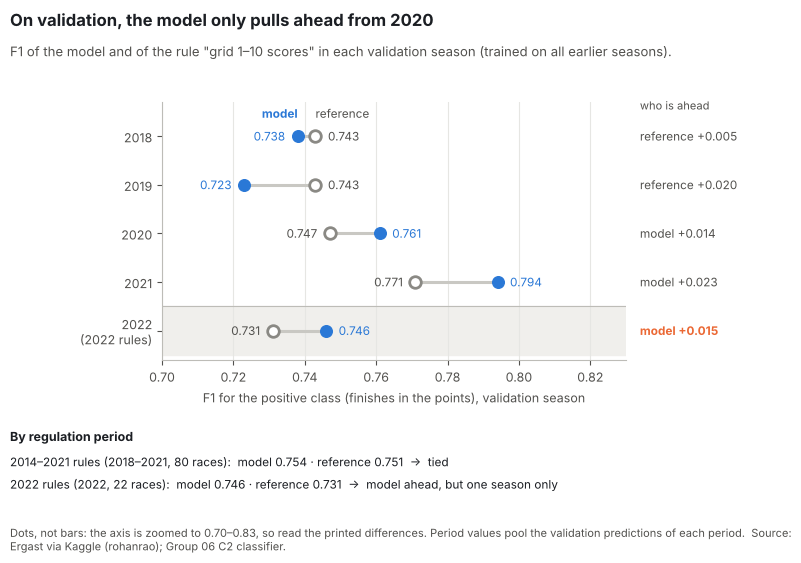

In [4]:
system_style()
fig, ax = plt.subplots(figsize=(W, 5.6))
fig.subplots_adjust(left=0.20, right=0.78, top=0.82, bottom=0.36)
v = val.iloc[::-1].reset_index(drop=True)                    # time order, top to bottom (2022 at the bottom)
v["m3"], v["r3"] = v["f1_model"].round(3), v["f1_reference"].round(3)
y = np.arange(len(v))
ax.axhspan(-0.5, 0.5, color=BAND, zorder=0)                   # the 2022-rules season on the light band
ax.axhline(0.5, color="#bdbcb7", lw=0.8)
for i, r in v.iterrows():
    ax.plot([r.r3, r.m3], [i, i], color="#c9c8c3", lw=2.2, zorder=1)
    ax.scatter(r.r3, i, s=70, facecolor="white", edgecolor=REF, lw=2, zorder=3)
    ax.scatter(r.m3, i, s=70, color=MODEL, zorder=3)
    for val_, who in ((r.m3, "model"), (r.r3, "ref")):
        is_left = val_ == min(r.m3, r.r3)
        ax.text(val_ + (-0.0035 if is_left else 0.0035), i, f"{val_:.3f}", va="center",
                ha="right" if is_left else "left", fontsize=8.5, color=MODEL if who == "model" else INK2)
    d = round(r.m3 - r.r3, 3)
    ax.text(1.03, i, f"{'model' if d > 0 else 'reference'} +{abs(d):.3f}", transform=ax.get_yaxis_transform(),
            va="center", ha="left", fontsize=8.5, color=ACCENT if r.season == 2022 else INK2,
            fontweight="bold" if r.season == 2022 else "normal")
ax.text(1.03, len(v) - 0.45, "who is ahead", transform=ax.get_yaxis_transform(), fontsize=8, color=INK2, ha="left")
top = len(v) - 1
ax.text(v.loc[top, "m3"], top + 0.38, "model", color=MODEL, fontsize=8.5, ha="right", fontweight="bold")
ax.text(v.loc[top, "r3"], top + 0.38, "reference", color=INK2, fontsize=8.5, ha="left")
ax.set_yticks(y, [f"{s}\n(2022 rules)" if s >= 2022 else str(s) for s in v["season"]])
ax.set_xlim(0.70, 0.83); ax.set_ylim(-0.6, len(v) - 0.3)
ax.grid(axis="y", visible=False)
ax.set_xlabel("F1 for the positive class (finishes in the points), validation season")

o, n = per.loc["2014–2021 rules"], per.loc["2022 rules"]
races_old, races_new = int(val.loc[val["season"] < 2022, "races"].sum()), int(val.loc[val["season"] == 2022, "races"].iloc[0])
fig.text(0.01, 0.215, "By regulation period", fontsize=9, color=INK, fontweight="bold")
fig.text(0.01, 0.170, f"2014–2021 rules (2018–2021, {races_old} races):  model {o.f1_model:.3f} · reference "
         f"{o.f1_reference:.3f}  →  tied", fontsize=8.5, color=INK)
fig.text(0.01, 0.130, f"2022 rules (2022, {races_new} races):  model {n.f1_model:.3f} · reference {n.f1_reference:.3f}  →  "
         "model ahead, but one season only", fontsize=8.5, color=INK)
headline(fig, "On validation, the model only pulls ahead from 2020",
         "F1 of the model and of the rule \"grid 1–10 scores\" in each validation season (trained on all earlier seasons).",
         "Dots, not bars: the axis is zoomed to 0.70–0.83, so read the printed differences. Period values pool the "
         "validation predictions of each period.")
save(fig, "V1_after_validation_dumbbell")

**What changed.** Bars → **dots on a common position scale** joined by a line (a dumbbell): position is the most accurate
channel for comparing two values, and dots do not suggest a length from zero, so the zoomed axis no longer exaggerates.
Values have **3 decimals** and the **difference is printed** for each season. Direct labels replace the legend. Seasons run in
time order and the **2022 rules** season sits on the light band, with a **period summary** at the right (feedback: results by
regulation period). The only orange element is the 2022 difference, the point the reader must not over-read.

## 2. View 2 · Error types on the final test (2023–2024)
**Question.** On the test seasons, which kind of error does the model reduce compared with the grid rule? **Task:** *compare*
false positives and false negatives of the model and the reference, and *identify* the larger reduction.

### 2a. Before (C2 version)

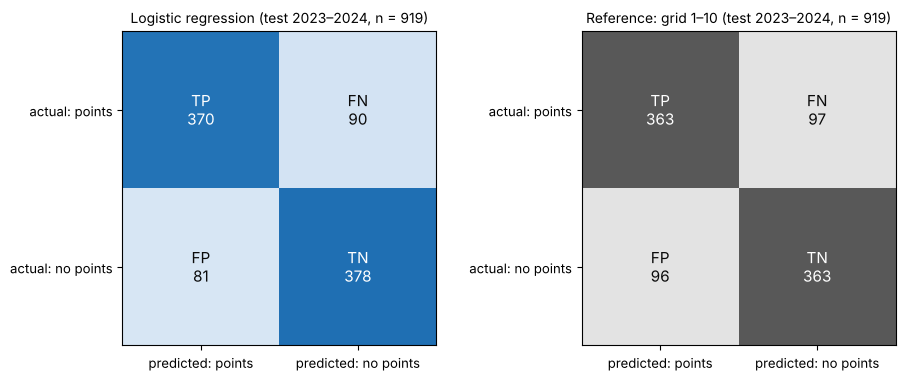

In [5]:
y_t = test["top10"].to_numpy()
plt.rcdefaults()
plt.rcParams.update({"figure.facecolor": "white", "font.size": 9.5})
fig, axes = plt.subplots(1, 2, figsize=(W + 1.5, 3.9))
for ax, (name, col), cmap in zip(axes, [("Logistic regression", "pred_model"), ("Reference: grid 1–10", "pred_reference")],
                                 ["Blues", "Greys"]):
    cm = confusion_matrix(y_t, test[col], labels=[1, 0])
    ax.imshow(cm, cmap=cmap, vmin=0, vmax=500)
    labels = [["TP", "FN"], ["FP", "TN"]]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{labels[i][j]}\n{cm[i, j]}", ha="center", va="center", fontsize=11,
                    color="white" if cm[i, j] > 250 else "#0b0b0b")
    ax.set_xticks([0, 1], ["predicted: points", "predicted: no points"]); ax.set_yticks([0, 1], ["actual: points", "actual: no points"])
    ax.grid(False); ax.set_title(f"{name} (test 2023–2024, n = {len(y_t)})", fontsize=10)
fig.tight_layout()
save(fig, "V2_before_confusion_matrices")

**Reading problems.** (1) The two matrices use **different colour scales** (blue vs grey), so the reader compares shades
across two palettes, which is hard and inaccurate. (2) The darkest cells are the **correct** predictions (TP, TN), so the
eye goes to what both rules do well, not to the errors the task is about. (3) To compare FP 81 vs 96 the reader must jump
between two separate panels. (4) There is no title with the finding and no period or F1 context.

### 2b. After (W3 version)

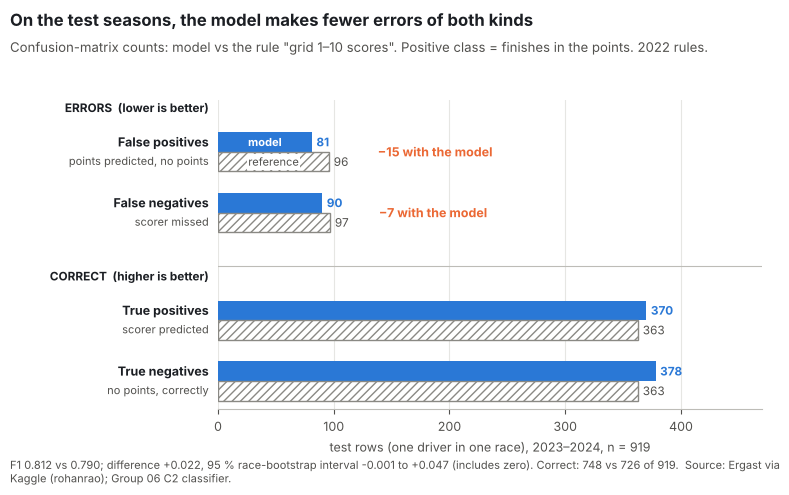

In [6]:
def cells(col):
    tp, fn, fp, tn = confusion_matrix(y_t, test[col], labels=[1, 0]).ravel()
    return {"FP": fp, "FN": fn, "TP": tp, "TN": tn}
cm_m, cm_r = cells("pred_model"), cells("pred_reference")

# race bootstrap of the F1 difference (same seed and procedure as C2)
rng = np.random.default_rng(2026)
by_race = {rid: g for rid, g in test.groupby("raceId")}
ids = np.array(list(by_race))
diff = []
for _ in range(2000):
    s = pd.concat([by_race[r] for r in rng.choice(ids, len(ids))])
    diff.append(f1_score(s["top10"], s["pred_model"]) - f1_score(s["top10"], s["pred_reference"]))
lo, hi = np.percentile(diff, [2.5, 97.5])
f1_m, f1_r = f1_score(y_t, test["pred_model"]), f1_score(y_t, test["pred_reference"])

system_style()
rows = [("FP", "False positives", "points predicted, no points"), ("FN", "False negatives", "scorer missed"),
        ("TP", "True positives", "scorer predicted"), ("TN", "True negatives", "no points, correctly")]
ypos = [5.2, 3.9, 1.6, 0.3]                                   # errors first, a gap, then correct predictions
fig, ax = plt.subplots(figsize=(W, 4.9))
fig.subplots_adjust(left=0.27, right=0.95, top=0.80, bottom=0.17)
h = 0.42
for (k, lab, desc), yy in zip(rows, ypos):
    ax.barh(yy + h / 2, cm_m[k], h, color=MODEL)
    ax.barh(yy - h / 2, cm_r[k], h, color="white", edgecolor=REF, hatch="////", lw=1)
    ax.text(cm_m[k] + 4, yy + h / 2, f"{cm_m[k]}", va="center", fontsize=8.5, color=MODEL, fontweight="bold")
    ax.text(cm_r[k] + 4, yy - h / 2, f"{cm_r[k]}", va="center", fontsize=8.5, color=INK2)
    ax.text(-8, yy + 0.05, lab, ha="right", va="bottom", fontsize=9, color=INK, fontweight="bold")
    ax.text(-8, yy - 0.05, desc, ha="right", va="top", fontsize=8, color=INK2)
    if k in ("FP", "FN"):
        ax.text(max(cm_m[k], cm_r[k]) + 42, yy, f"{cm_m[k] - cm_r[k]:+d} with the model".replace("-", "−"), va="center",
                fontsize=9, color=ACCENT, fontweight="bold")
ax.text(cm_m["FP"] / 2, ypos[0] + h / 2, "model", color="white", fontsize=8, ha="center", va="center", fontweight="bold")
ax.text(cm_r["FP"] / 2, ypos[0] - h / 2, "reference", color=INK2, fontsize=8, ha="center", va="center",
        bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.text(-8, 6.05, "ERRORS  (lower is better)", ha="right", fontsize=8.5, color=INK, fontweight="bold")
ax.text(-8, 2.45, "CORRECT  (higher is better)", ha="right", fontsize=8.5, color=INK, fontweight="bold")
ax.axhline(2.75, color="#bdbcb7", lw=0.8)
ax.set_yticks([]); ax.set_ylim(-0.3, 6.3); ax.set_xlim(0, 470)
ax.spines["left"].set_visible(False); ax.grid(axis="y", visible=False)
ax.set_xlabel(f"test rows (one driver in one race), 2023–2024, n = {len(test)}")
headline(fig, "On the test seasons, the model makes fewer errors of both kinds",
         "Confusion-matrix counts: model vs the rule \"grid 1–10 scores\". Positive class = finishes in the points. 2022 rules.",
         f"F1 {f1_m:.3f} vs {f1_r:.3f}; difference {f1_m - f1_r:+.3f}, 95 % race-bootstrap interval {lo:+.3f} to {hi:+.3f} "
         f"(includes zero). Correct: {cm_m['TP'] + cm_m['TN']} vs {cm_r['TP'] + cm_r['TN']} of {len(test)}.")
save(fig, "V2_after_error_bars")

**What changed.** Shades in two palettes → **bar length on one common scale from 0**, with the model bar directly above the
reference bar for each cell, so every comparison is a short vertical eye movement. **Errors come first** under their own
heading and the reductions (−15 false positives, −7 false negatives) are the orange call-outs; the correct cells stay
below as context. The model is a **solid blue** bar and the reference a **hatched grey** bar, so the two can be told apart
without colour. The title states the finding, and the note gives F1 and its race-bootstrap interval, which **includes
zero**: the reduction is small.

## 3. View 3 · What the model adds: the 102 disagreements with the grid
**Question.** When the model and the grid rule disagree, which drivers does the model change, and how often is it right?
**Task:** *identify* the two groups of drivers the model changes and *summarize* how often it is right in each.

### 3a. Before (C2 version: slide 6 of the presentation)

In [7]:
dis = test[test["pred_model"] != test["pred_reference"]]
up = dis[dis["pred_model"] == 1]                              # model: points, grid rule: no (started P11+)
down = dis[dis["pred_model"] == 0]                            # model: no points, grid rule: points (started P1–P10)
up_right, down_right = int((up["top10"] == 1).sum()), int((down["top10"] == 0).sum())

plt.rcdefaults()
fig = plt.figure(figsize=(W, 3.6))
fig.patch.set_facecolor("#f4f3ef")
fig.text(0.04, 0.90, "05 · WHAT THE MODEL ADDS", fontsize=8, color="#2566b0", fontweight="bold")
fig.text(0.04, 0.78, "It corrects the grid with the team's strength", fontsize=14, color=INK, fontweight="bold")
fig.text(0.04, 0.42, f"{len(dis)}", fontsize=40, color="#2566b0", fontweight="bold")
fig.text(0.04, 0.20, "test rows where model and\nreference disagree; the model is\n"
         f"right in {up_right + down_right} ({(up_right + down_right) / len(dis):.0%})", fontsize=9, color=INK)
for yb, colr, t1, t2 in [(0.47, MODEL, f"Promotes {len(up)} drivers starting P11+",
                          f"All from teams ranked 1st–6th · {up_right} of them scored"),
                         (0.15, ACCENT, f"Demotes {len(down)} drivers starting P1–P10",
                          f"All from teams ranked 7th or lower · {down_right} did not score")]:
    fig.patches.append(FancyBboxPatch((0.36, yb), 0.60, 0.25, boxstyle="round,pad=0.01", transform=fig.transFigure,
                                      facecolor="white", edgecolor="#dcdad3"))
    fig.text(0.40, yb + 0.125, "●", fontsize=22, color=colr, ha="center", va="center")
    fig.text(0.45, yb + 0.16, t1, fontsize=10.5, fontweight="bold", color=INK)
    fig.text(0.45, yb + 0.05, t2, fontsize=9, color=INK2)
save(fig, "V3_before_disagreement_cards")

<Figure size 800x360 with 0 Axes>

**Reading problems.** (1) There is **no chart**: the reader must read four numbers in text and work out the shares
(31 of 47, 31 of 55) to compare the groups. (2) The coloured dots carry **no data meaning**, and orange marks a category
here while elsewhere in C2 it was a highlight. (3) "Promotes/demotes" hides what was actually compared: the grid rule's
prediction vs the model's prediction. (4) The large "102" draws the eye first, but the task is about how often the model is
right.

### 3b. After (W3 version)

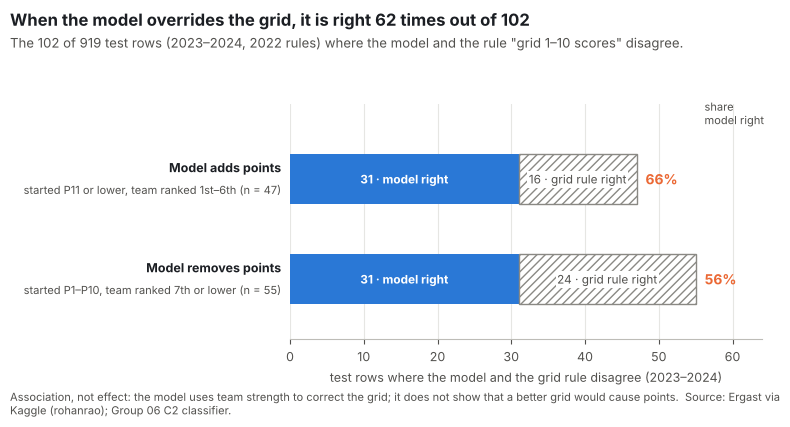

In [8]:
system_style()
fig, ax = plt.subplots(figsize=(W, 4.2))
fig.subplots_adjust(left=0.36, right=0.95, top=0.76, bottom=0.20)
groups = [("Model adds points", f"started P11 or lower, team ranked 1st–6th (n = {len(up)})", up_right, len(up) - up_right, 1.0),
          ("Model removes points", f"started P1–P10, team ranked 7th or lower (n = {len(down)})", down_right,
           len(down) - down_right, 0.0)]
h = 0.5
for title_, desc, right, wrong, yy in groups:
    ax.barh(yy, right, h, color=MODEL)
    ax.barh(yy, wrong, h, left=right, color="white", edgecolor=REF, hatch="////", lw=1)
    ax.text(right / 2, yy, f"{right} · model right", ha="center", va="center", color="white", fontsize=8.5, fontweight="bold")
    ax.text(right + wrong / 2, yy, f"{wrong} · grid rule right", ha="center", va="center", color=INK2, fontsize=8.5,
            bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.text(right + wrong + 1.2, yy, f"{right / (right + wrong):.0%}", va="center", fontsize=10, color=ACCENT, fontweight="bold")
    ax.text(-1.2, yy + 0.04, title_, ha="right", va="bottom", fontsize=9, color=INK, fontweight="bold")
    ax.text(-1.2, yy - 0.04, desc, ha="right", va="top", fontsize=8, color=INK2)
ax.text(len(down) + 1.2, 1.55, "share\nmodel right", fontsize=8, color=INK2)
ax.set_yticks([]); ax.set_ylim(-0.6, 1.75); ax.set_xlim(0, 64)
ax.spines["left"].set_visible(False); ax.grid(axis="y", visible=False)
ax.set_xlabel("test rows where the model and the grid rule disagree (2023–2024)")
headline(fig, f"When the model overrides the grid, it is right {up_right + down_right} times out of {len(dis)}",
         f"The {len(dis)} of {len(test)} test rows (2023–2024, 2022 rules) where the model and the rule \"grid 1–10 scores\" disagree.",
         "Association, not effect: the model uses team strength to correct the grid; it does not show that a better grid "
         "would cause points.")
save(fig, "V3_after_disagreement_bars")

**What changed.** Text cards → **two stacked bars on a common scale from 0**, one per group, each split into "model right"
(solid blue) and "grid rule right" (hatched grey). Length shows the counts, and the orange share at the end gives the
**summary per group** (66 % and 56 %). The groups are described by what defines them (grid slot and team rank), not by
"promotes/demotes". The blue/grey meaning is the same as in views 1 and 2 (model vs reference), and the decorative coloured
dots are gone. The note keeps the C2 rule: association, not effect.

## 4. Values used in the document (all from the C2 results)

In [9]:
pd.DataFrame({
    "value": [f"{val['f1_model'].iloc[-1]:.3f} vs {val['f1_reference'].iloc[-1]:.3f}",
              f"{per.loc['2014–2021 rules', 'f1_model']:.3f} vs {per.loc['2014–2021 rules', 'f1_reference']:.3f}",
              f"{f1_m:.3f} vs {f1_r:.3f}", f"{f1_m - f1_r:+.3f} [{lo:+.3f}, {hi:+.3f}]",
              f"{cm_m['FP']} vs {cm_r['FP']}", f"{cm_m['FN']} vs {cm_r['FN']}",
              f"{len(dis)} (model right in {up_right + down_right})",
              f"{up_right} of {len(up)} | {down_right} of {len(down)}"]},
    index=["Validation F1 2022 (model vs reference)", "Validation F1 2014–2021, pooled (model vs reference)",
           "Test F1 (model vs reference)", "Test F1 difference [95 % race bootstrap]",
           "Test false positives", "Test false negatives", "Test disagreements",
           "Model right: adds points | removes points"])

,value
Validation F1 2022 (model vs reference),0.746 vs 0.731
"Validation F1 2014–2021, pooled (model vs reference)",0.754 vs 0.751
Test F1 (model vs reference),0.812 vs 0.790
Test F1 difference [95 % race bootstrap],"+0.022 [-0.001, +0.047]"
Test false positives,81 vs 96
Test false negatives,90 vs 97
Test disagreements,102 (model right in 62)
Model right: adds points | removes points,31 of 47 | 31 of 55
